# VARS-TOOL: A Toolbox for Comprehensive, Efficient, and Robust Sensitivity and Uncertainty Analysis (HBV-SASK, Oldman River)

__Saman Razavi__, Global Institute for Water Security; School of Environment and Sustainability; Department of Civil, Geological, and Environmental Engineering, University of Saskatchewan, Saskatoon, Saskatchewan, Canada

__Razi Sheikholeslami__, Global Institute for Water Security; School of Environment and Sustainability, University of Saskatchewan, Saskatoon, Saskatchewan, Canada

__Hoshin V. Gupta__, Department of Hydrology & Atmospheric Sciences, The University of Arizona, Tucson, AZ, USA

__Amin Haghnegahdar__, Global Institute for Water Security; School of Environment and Sustainability, University of Saskatchewan, Saskatoon, Saskatchewan, Canada

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the HBV-SASK rainfall-runoff model that ships with VARS-TOOL [[1]][R1], set up for the Oldman River at Waldron's Corner, Alberta. It runs in Python 3 with numpy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about half a minute. The model is `hbv_sask_model.py`, a numpy reimplementation written for this data set from the paper's description; `DATA.md` describes the files and how it was checked against the VARS-TOOL implementation.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import hbv_sask_model as hm

SEED = 689                        # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = ['TT', 'C0', 'ETF', 'LP', 'FC', r'$\beta$', 'FRAC', 'K1', r'$\alpha$', 'K2', 'UBAS', 'PM']
qlabels = ['NSE (-)', r'$Q_{\mathrm{mean}}$ (m$^3$/s)', r'$Q_{\mathrm{peak}}$ (m$^3$/s)']

### Summary

Razavi et al. [[1]][R1] present VARS-TOOL, a toolbox for variogram-, variance- and derivative-based sensitivity analysis, and ship with it the daily conceptual hydrologic model HBV-SASK with 12 parameters (Table 2, p. 105) and forcing for the Oldman River basin. We reimplement the model in numpy with forward-sensitivity gradients, sample the 12 parameters uniformly on the Table 2 box ($M = 2000$), and study the Nash–Sutcliffe efficiency (NSE) of simulated daily streamflow over 1982–1996, with the mean flow and the mean annual peak flow as secondary outputs. The NSE has a dominant direction ($\lambda_1/\lambda_2 = 3.91$, a cubic in one active variable has leave-one-out $R^2 = 0.906$) made mostly of the precipitation multiplier PM, the fast-reservoir fraction FRAC, the melt factor C0 and the field capacity FC, the same four parameters that lead our Sobol' total-effect indices and the VARS-TOOL tutorial's variance-based ranking for this output.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

HBV-SASK is "an interpretation of Hydrologiska Byråns Vattenbalansavdelning model (Lindström et al., 1997)" [[2]][R2] [[1]][R1] (Sect. 9, p. 104), lumped over the basin and run on a daily step. Fig. 9 (p. 104) gives its structure and process equations, and Sect. 9 the potential evapotranspiration. With daily precipitation $P_t$ (mm) and temperature $T_t$ (°C), and states at the start of day $t$ (snow water equivalent SWE, soil moisture SM and the storages $S_1$, $S_2$ of the fast and slow reservoirs, all in mm), one day is

$$
\begin{aligned}
P &= \mathrm{PM}\,P_t;\qquad T_t < \mathrm{TT}: \ \mathrm{SWE} \mathrel{+}= P,\ \ \text{ponding} = 0;\qquad
T_t \ge \mathrm{TT}: \ \mathrm{MS} = \min\{C_0\,(T_t - \mathrm{TT}),\ \mathrm{SWE}\},\ \ \mathrm{SWE} \mathrel{-}= \mathrm{MS},\ \ \text{ponding} = P + \mathrm{MS},\\
\mathrm{PET} &= \max\{0,\ (1 + \mathrm{ETF}\,(T_t - T_{mth}))\,\mathrm{PET}_{mth}\},\qquad
\mathrm{AET} = \min\{\mathrm{SM},\ \mathrm{PET}\,\min(\mathrm{SM}/(\mathrm{LP}\,\mathrm{FC}),\,1)\},\\
R &= \text{ponding}\,\min(\mathrm{SM}/\mathrm{FC},\,1)^{\beta},\qquad Q_1 = \min\{K_1 S_1^{\alpha},\ S_1\},\qquad Q_2 = K_2 S_2,\\
\mathrm{SM} &\mathrel{+}= \text{ponding} - R - \mathrm{AET},\qquad S_1 \mathrel{+}= \mathrm{FRAC}\,R - Q_1,\qquad S_2 \mathrel{+}= (1-\mathrm{FRAC})\,R - Q_2,\\
Q_t &= \Big(\textstyle\sum_{k=1}^{3} w_k(\mathrm{UBAS})\,Q_{1,t-k+1} + Q_2\Big)\,A/86.4 \quad (\mathrm{m^3/s}),
\end{aligned}
$$

where $T_{mth}$ and $\mathrm{PET}_{mth}$ are the long-term monthly means supplied with the forcing, $A = 1434.73$ km² is the basin area (p. 105), and $w_k$ is the area over day $k$ of a symmetric triangle of unit area on $[0, \mathrm{UBAS}]$ days (the watershed unit hydrograph of Fig. 9). Fig. 9 prints the process equations without the caps: AET = PET·(SM/LP), $R = (\mathrm{RF} + \mathrm{MS})(\mathrm{SM}/\mathrm{FC})^\beta$, $Q_1 = K_1 S_1^\alpha$, $Q_2 = K_2 S_2$, and MS = C0·(T−TT); Table 2 defines LP as a multiplier of FC. The caps (the minima above), the order of the updates within a day and the unit-hydrograph weights are those of the VARS-TOOL Python implementation, which we ran as an outside tool to check this port (it reproduces the daily flows of that implementation to a relative $10^{-15}$, `DATA.md`).

The run starts on 1979-01-01 from the initial states of the VARS-TOOL Oldman set-up and ends on 2008-12-31. The quantities of interest are computed over 1982-01-01 to 1996-12-31, the window of the VARS-TOOL HBV-SASK tutorial (the first three years are spin-up; the paper itself defines no scalar output for the Oldman case):

* **NSE**, the Nash–Sutcliffe efficiency [[5]][R5] $1 - \sum_t (Q_t - Q^{obs}_t)^2 / \sum_t (Q^{obs}_t - \bar Q^{obs})^2$ against the observed daily flow at gauge 05AA023 (primary output);
* $Q_{\mathrm{mean}}$, the mean simulated flow (m³/s), and $Q_{\mathrm{peak}}$, the mean over the 15 calendar years of the annual maximum daily simulated flow (m³/s), two flow metrics chosen for this data set.

The 12 inputs and their ranges are Table 2 (p. 105). The paper gives bounds only; like the VARS-TOOL tutorials, we take the parameters independent and uniform on those bounds. The "tutorial" column is the parameter set of the VARS-TOOL tutorial files, not a value from the paper.

In [2]:
desc = ['air temperature threshold for rain/snow and melt', 'base melt factor', 'temperature anomaly correction of PET',
        'PET limit as a multiplier of FC', 'field capacity of the soil', 'exponent of the soil release equation',
        'fraction of soil release to the fast reservoir', 'fast reservoir coefficient', 'fast reservoir exponent',
        'slow reservoir coefficient', 'base of the unit hydrograph', 'precipitation multiplier']
print(f"{'#':>2s} {'name':6s} {'units':12s} {'lower':>7s} {'upper':>7s} {'tutorial':>8s}  description (Table 2, p. 105)")
for j, n in enumerate(hm.NAMES):
    print(f'{j + 1:2d} {n:6s} {hm.UNITS[j]:12s} {hm.LB[j]:7g} {hm.UB[j]:7g} {hm.TUTORIAL[j]:8g}  {desc[j]}')
print(f'\nwatershed area {hm.AREA_KM2} km2; initial (SWE, SMS, S1, S2) = {hm.STATE0.tolist()} mm; '
      f'{hm.NDAYS} days 1979-01-01 to 2008-12-31; QoI window {hm.I1 - hm.I0} days 1982-01-01 to 1996-12-31')
qw = hm.Q_OBS[hm.I0:hm.I1]
print(f'observed flow in the window: mean {qw.mean():.2f} m3/s, largest {qw.max():.1f} m3/s')
nyr = hm.NDAYS / 365.25
p_ann = hm.P_OBS.sum() / nyr
q_ann_mm = hm.Q_OBS.sum() * 86.4 / hm.AREA_KM2 / nyr
print(f'whole record 1979-2008: mean annual precipitation {p_ann:.0f} mm, mean observed flow {hm.Q_OBS.mean():.2f} m3/s '
      f'({q_ann_mm:.0f} mm/year), runoff ratio {q_ann_mm / p_ann:.2f}')
f0 = hm.qoi(hm.TUTORIAL)[0]
print(f'at the tutorial parameter values: NSE = {f0[0]:.6f}, Qmean = {f0[1]:.3f} m3/s, Qpeak = {f0[2]:.2f} m3/s')

 # name   units          lower   upper tutorial  description (Table 2, p. 105)
 1 TT     degC              -4       4        0  air temperature threshold for rain/snow and melt
 2 C0     mm/degC/day        0      10        1  base melt factor
 3 ETF    1/degC             0       1      0.1  temperature anomaly correction of PET
 4 LP     -                  0       1      0.3  PET limit as a multiplier of FC
 5 FC     mm                50     500      250  field capacity of the soil
 6 beta   -                  1       3        2  exponent of the soil release equation
 7 FRAC   -                0.1     0.9      0.7  fraction of soil release to the fast reservoir
 8 K1     1/day           0.05       1     0.05  fast reservoir coefficient
 9 alpha  -                  1       3      1.5  fast reservoir exponent
10 K2     1/day              0    0.05     0.01  slow reservoir coefficient
11 UBAS   day                1       3        1  base of the unit hydrograph
12 PM     -                0

at the tutorial parameter values: NSE = 0.577190, Qmean = 10.050 m3/s, Qpeak = 96.27 m3/s


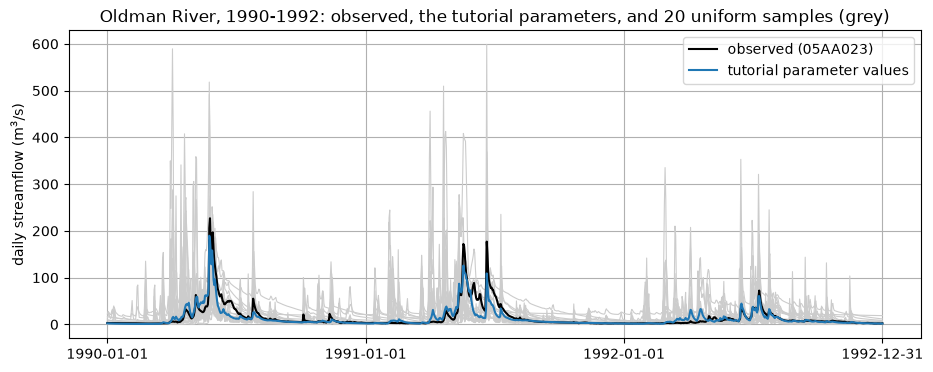

In [3]:
rng_fig = np.random.default_rng(SEED)
Xfig = hm.LB + (hm.UB - hm.LB) * rng_fig.random((20, 12))
qs = hm.simulate(np.vstack([hm.TUTORIAL, Xfig]))
days = np.arange(hm.NDAYS)
a, b = hm._day_index((1990, 1, 1)), hm._day_index((1992, 12, 31)) + 1
fig, ax = plt.subplots(figsize=(11, 4))
for q in qs[1:]:
    ax.plot(days[a:b], q[a:b], color='0.8', lw=0.8)
ax.plot(days[a:b], hm.Q_OBS[a:b], 'k', lw=1.5, label='observed (05AA023)')
ax.plot(days[a:b], qs[0, a:b], 'C0', lw=1.5, label='tutorial parameter values')
ticks = [hm._day_index((y, 1, 1)) for y in (1990, 1991, 1992)] + [b - 1]
ax.set_xticks(ticks)
ax.set_xticklabels(['1990-01-01', '1991-01-01', '1992-01-01', '1992-12-31'])
ax.set_ylabel('daily streamflow (m$^3$/s)')
ax.set_title('Oldman River, 1990-1992: observed, the tutorial parameters, and 20 uniform samples (grey)')
ax.legend()
ax.grid(True)
plt.close(fig)
fig

At the tutorial parameter values the simulated flow follows the snowmelt-driven spring peaks of the Oldman River (NSE = 0.577 over 1982–1996), while uniform samples of the Table 2 box range from far too little to several times too much runoff.

### Load data

`generate_data.py` drew $M = 2000$ independent uniform (Monte Carlo) samples of the 12 parameters (seed 689) and wrote the physical inputs, the three outputs and their gradients with respect to the physical parameters; it takes one to three minutes (`DATA.md`). For the 11 parameters other than TT the gradients are the exact forward (tangent) sensitivities of the daily recursion. The recursion has kinks (the minima above, the PET cut-off) where one-sided derivatives differ, which matters on a set of measure zero. TT is different: when TT crosses the temperature of a wet day, that day's precipitation switches between rain and snow, and every output jumps. The forcing temperatures are recorded to 0.01 °C, so the outputs are piecewise smooth in TT with a jump wherever TT passes a recorded wet-day temperature, and the tangent derivative, exact between jumps, misses them (`check_accuracy.py` finds that the jumps carry a median 26 % of the change in NSE over ±0.25 °C). The TT column of `gradients.csv` is therefore the central difference TT ± 0.1 °C, $(f(\mathrm{TT} + 0.1) - f(\mathrm{TT} - 0.1))/0.2$, over an interval 0.2 °C wide that contains many recorded wet-day temperatures; it is a choice of this data set, and at single samples its value depends on the step (`check_accuracy.py`, check 2, in `DATA.md`). The tangent column is stored in `tt_tangent.csv`, and we compare the two below.

In [4]:
X = np.loadtxt('inputs.csv', delimiter=',')                         # (M, 12) physical parameters
f = np.loadtxt('outputs.csv', delimiter=',')                        # (M, 3) NSE, Qmean, Qpeak
G = np.loadtxt('gradients.csv', delimiter=',').reshape(-1, 3, 12)   # (M, 3, 12) d(QoI)/d(parameter)
Gtt = np.loadtxt('tt_tangent.csv', delimiter=',')                   # (M, 3) tangent d(QoI)/dTT
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}, tangent TT column {Gtt.shape}')
rows = [0, 1, 2, 3, 4]
f5 = hm.qoi(X[rows])
rel5 = np.max(np.abs(f5 - f[rows]) / np.abs(f[rows]))
print(f'model vs outputs.csv at rows {rows}: max relative difference below 1e-12: {rel5 < 1e-12}')
inside = np.all((X >= hm.LB) & (X <= hm.UB))
print(f'all samples inside the Table 2 box: {inside}')
for q in range(3):
    print(f'{hm.QOI_NAMES[q]:6s} range [{f[:, q].min():.4g}, {f[:, q].max():.4g}], median {np.median(f[:, q]):.4g}')
print(f'NSE < 0 (worse than the observed mean) at {np.sum(f[:, 0] < 0)} of {len(f)} samples; NSE > 0.5 at {np.sum(f[:, 0] > 0.5)}')

inputs (2000, 12), outputs (2000, 3), gradients (2000, 3, 12), tangent TT column (2000, 3)


model vs outputs.csv at rows [0, 1, 2, 3, 4]: max relative difference below 1e-12: True
all samples inside the Table 2 box: True
NSE    range [-21.26, 0.6965], median -0.2804
Qmean  range [0.09681, 39.04], median 14.83
Qpeak  range [0.5838, 882.2], median 161.1
NSE < 0 (worse than the observed mean) at 1381 of 2000 samples; NSE > 0.5 at 36


The model reproduces the stored outputs at the first five rows to better than $10^{-12}$ relative, and every sample lies in the Table 2 box. The NSE spans $[-21.26, 0.6965]$ with median $-0.28$: 1381 of the 2000 samples do worse than the observed mean and 36 have NSE > 0.5, so the output is dominated by the poor fits that fill most of the box. No sample is outside the model's meaning; a low NSE is a bad fit, not a failed run.

### Estimate the subspace

We have gradients for every sample, so we use the gradient-based estimator (`estimator="as"`) in the normalized coordinates $x_i \in [-1, 1]$ (each parameter mapped linearly from its Table 2 range), with 500 bootstrap replicates. The paper has no eigenvector figures, so the signs follow a stated rule: each of the first three eigenvectors is signed so that $\mathbf w_k^T\mathbf x$ has positive sample covariance with the output (`ac.orient(by="covariance")`).

In [5]:
space = ac.Uniform(hm.LB, hm.UB, names=hm.NAMES)
N_CHOSEN = [1, 3, 2]              # dimensions chosen below (NSE, Qmean, Qpeak); the gap rule's choice is printed
subs = []
for q in range(3):
    sub = ac.active_subspace(space=space, X=X, f=f[:, q], grads=G[:, q], estimator='as', nboot=500, rng=SEED)
    sub = ac.orient(sub, by='covariance', X=X, f=f[:, q], columns=3)
    ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
    sub = ac.with_dimension(sub, N_CHOSEN[q])
    subs.append(sub)
    lam = sub.eigenvalues
    print(f'{hm.QOI_NAMES[q]}: eigenvalues / lambda_1 = {np.array2string(lam / lam[0], precision=3, max_line_width=150)}')
    print(f'   lambda_k/lambda_k+1 (k = 1..5) = {np.array2string(lam[:5] / lam[1:6], precision=2)}; gap rule n = {k_hat}')

NSE: eigenvalues / lambda_1 = [1.000e+00 2.556e-01 7.887e-02 3.199e-02 2.646e-02 2.363e-02 1.682e-02 1.211e-02 6.681e-03 5.765e-03 2.248e-03 5.950e-04]
   lambda_k/lambda_k+1 (k = 1..5) = [3.91 3.24 2.47 1.21 1.12]; gap rule n = 1


Qmean: eigenvalues / lambda_1 = [1.000e+00 5.508e-01 2.293e-01 6.430e-03 3.976e-03 1.484e-03 6.132e-04 5.082e-04 2.641e-05 1.908e-09 5.466e-11 2.572e-14]
   lambda_k/lambda_k+1 (k = 1..5) = [ 1.82  2.4  35.66  1.62  2.68]; gap rule n = 1


Qpeak: eigenvalues / lambda_1 = [1.    0.691 0.177 0.123 0.075 0.035 0.02  0.017 0.01  0.005 0.003 0.001]
   lambda_k/lambda_k+1 (k = 1..5) = [1.45 3.9  1.44 1.64 2.11]; gap rule n = 2


### Results

**Eigenvalues.** The figure shows the eigenvalues with 95 % bootstrap bands for NSE (left), $Q_{\mathrm{mean}}$ (middle) and $Q_{\mathrm{peak}}$ (right); the dotted line marks the dimension chosen below.

NSE: lambda_1 = 25.86, lambda_1/lambda_2 = 3.91 (bootstrap 2.5-97.5 % [2.82, 6.26]), lambda_2/lambda_3 = 3.24 ([1.63, 5.95]); share of trace outside the first n: n=1 0.315, n=2 0.140, n=3 0.086
Qmean: lambda_1 = 1154, lambda_1/lambda_2 = 1.82 (bootstrap 2.5-97.5 % [1.06, 4.46]), lambda_2/lambda_3 = 2.40 ([1.24, 3.50]); share of trace outside the first n: n=1 0.442, n=2 0.135, n=3 0.007
Qpeak: lambda_1 = 6.483e+04, lambda_1/lambda_2 = 1.45 (bootstrap 2.5-97.5 % [1.33, 1.67]), lambda_2/lambda_3 = 3.90 ([3.01, 4.83]); share of trace outside the first n: n=1 0.536, n=2 0.216, n=3 0.134


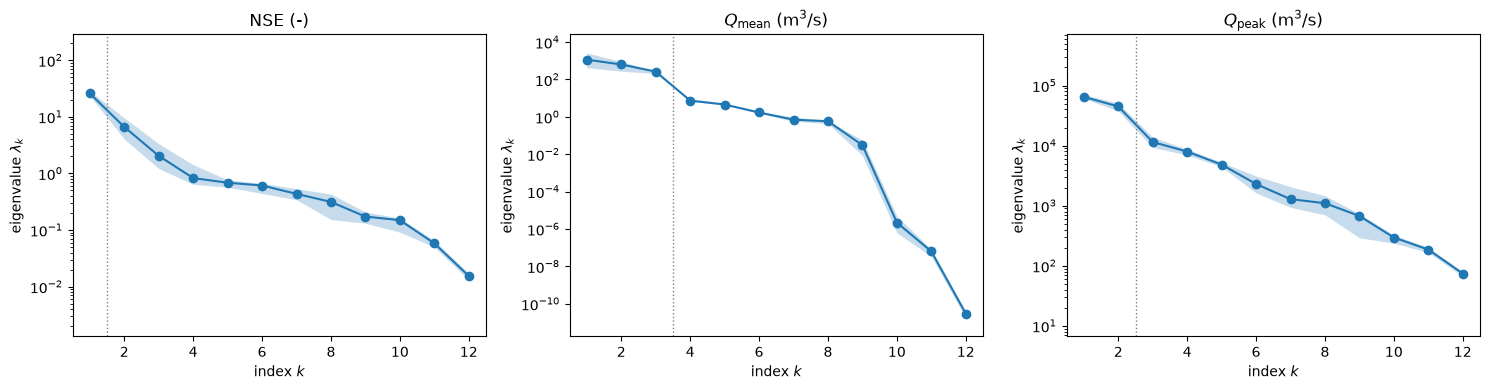

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for q in range(3):
    ac.plotting.plot_eigenvalues(subs[q], ax=axes[q])
    axes[q].set_title(qlabels[q])
fig.tight_layout()
plt.close(fig)
for q in range(3):
    b = subs[q].bootstrap_eigenvalues
    r12, r23 = b[:, 0] / b[:, 1], b[:, 1] / b[:, 2]
    lam = subs[q].eigenvalues
    print(f'{hm.QOI_NAMES[q]}: lambda_1 = {lam[0]:.4g}, lambda_1/lambda_2 = {lam[0] / lam[1]:.2f} '
          f'(bootstrap 2.5-97.5 % [{np.percentile(r12, 2.5):.2f}, {np.percentile(r12, 97.5):.2f}]), '
          f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f} ([{np.percentile(r23, 2.5):.2f}, {np.percentile(r23, 97.5):.2f}]); '
          f'share of trace outside the first n: n=1 {1 - lam[0] / lam.sum():.3f}, n=2 {1 - lam[:2].sum() / lam.sum():.3f}, '
          f'n=3 {1 - lam[:3].sum() / lam.sum():.3f}')
fig

For the NSE, $\lambda_1/\lambda_2 = 3.91$ (bootstrap 2.82–6.26) is the largest gap, and $\lambda_2/\lambda_3 = 3.24$ (1.63–5.95) is comparable to it; the first eigenvalue leaves 0.315 of the trace, the first two 0.140. For $Q_{\mathrm{peak}}$ the first two eigenvalues are close ($\lambda_1/\lambda_2 = 1.45$) and the gap follows them ($\lambda_2/\lambda_3 = 3.90$). For $Q_{\mathrm{mean}}$ the spectrum drops by a factor of 35.66 after the third eigenvalue, and the first three leave 0.007 of the trace; its smallest eigenvalues are tiny because the routing parameters (UBAS, K1, $\alpha$) hardly change a 15-year mean flow.

NSE: bootstrap mean subspace distance k = 1..5: [0.047 0.054 0.154 0.484 0.531]
Qmean: bootstrap mean subspace distance k = 1..5: [0.256 0.131 0.009 0.049 0.036]
Qpeak: bootstrap mean subspace distance k = 1..5: [0.116 0.039 0.102 0.08  0.102]


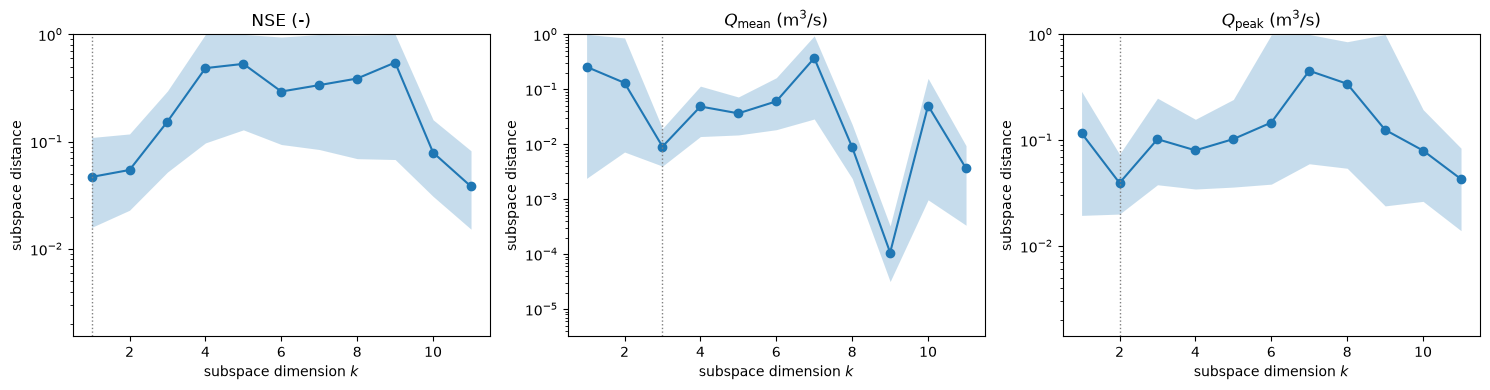

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for q in range(3):
    ac.plotting.plot_subspace_errors(subs[q], ax=axes[q])
    axes[q].set_title(qlabels[q])
    dist = subs[q].bootstrap_distances.mean(axis=0)
    print(f'{hm.QOI_NAMES[q]}: bootstrap mean subspace distance k = 1..5: {np.array2string(dist[:5], precision=3)}')
fig.tight_layout()
plt.close(fig)
fig

The bootstrap mean subspace distance for the NSE is 0.047 for $n = 1$ and 0.054 for $n = 2$, so both are well determined by 2000 samples, while $n = 3$ (0.154) is not. For $Q_{\mathrm{peak}}$ the two-dimensional subspace (0.039) is better determined than the first direction alone (0.116), as the close $\lambda_1$ and $\lambda_2$ suggest; for $Q_{\mathrm{mean}}$ the three-dimensional subspace has distance 0.009.

NSE w1 = [-0.102 -0.337  0.074 -0.08   0.287 -0.008 -0.508 -0.049 -0.084 -0.069  0.084 -0.708]; largest: PM -0.708, FRAC -0.508, C0 -0.337, FC +0.287
NSE w2 = [-0.217  0.923  0.006 -0.02   0.027 -0.009 -0.173 -0.015 -0.029 -0.027  0.018 -0.261]; largest: C0 +0.923, PM -0.261, TT -0.217, FRAC -0.173
Qmean w1 = [-1.246e-03  7.140e-03 -5.950e-03  7.415e-03 -1.035e-02 -4.093e-03  9.948e-03 -3.453e-07  2.498e-07  9.989e-01  1.054e-08  4.330e-02]; largest: K2 +0.999, PM +0.043, FC -0.010, FRAC +0.010
Qmean w2 = [-3.861e-02  9.893e-01 -2.769e-02  3.003e-02 -3.570e-02 -1.563e-02 -1.576e-04 -2.628e-07  8.242e-07 -1.350e-02  2.778e-08  1.282e-01]; largest: C0 +0.989, PM +0.128, TT -0.039, FC -0.036
Qpeak w1 = [ 0.171  0.538 -0.072  0.073 -0.253 -0.006  0.456  0.069  0.125  0.056 -0.105  0.603]; largest: PM +0.603, C0 +0.538, FRAC +0.456, FC -0.253
Qpeak w2 = [ 3.391e-01 -8.129e-01 -2.451e-02  2.463e-02 -8.514e-02  9.407e-05  2.035e-01  2.758e-02  5.221e-02  2.444e-02 -3.739e-02  4.110e-01]; larg

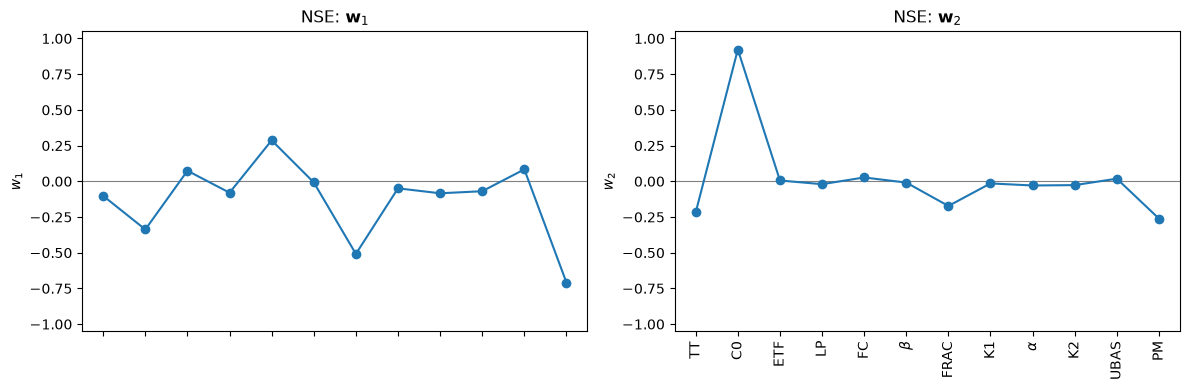

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ac.plotting.plot_eigenvectors(subs[0], indices=[0, 1], labels=labels, ax=list(axes))
axes[0].set_title(r'NSE: $\mathbf{w}_1$')
axes[1].set_title(r'NSE: $\mathbf{w}_2$')
fig.tight_layout()
plt.close(fig)
for q in range(3):
    W = subs[q].W
    for k in range(2):
        order_k = np.argsort(-np.abs(W[:, k]))[:4]
        print(f'{hm.QOI_NAMES[q]} w{k + 1} = {np.array2string(W[:, k], precision=3, max_line_width=160)}; largest: '
              + ', '.join(f'{hm.NAMES[i]} {W[i, k]:+.3f}' for i in order_k))
fig

In normalized coordinates the NSE increases along $\mathbf w_1$, whose largest entries are PM ($-0.708$), FRAC ($-0.508$), C0 ($-0.337$) and FC ($+0.287$): over most of the box the model makes too much quick runoff, and the fit improves with less precipitation, less soil release routed to the fast reservoir, slower melt and a larger soil store. $\mathbf w_2$ is mostly the melt factor C0 ($+0.923$), with PM ($-0.261$), TT ($-0.217$) and FRAC ($-0.173$). $Q_{\mathrm{peak}}$ has nearly the same first direction with the signs reversed (PM $+0.603$, C0 $+0.538$, FRAC $+0.456$, FC $-0.253$). The first direction of $Q_{\mathrm{mean}}$ is almost exactly K2 ($+0.999$) and its second C0 ($+0.989$), which the sufficient summary plots below explain.

NSE: y1 in [-1.68, 1.71], corr(y1, NSE) = 0.7655, Spearman = 0.8642
the 36 samples with NSE > 0.5 have y1 in [-0.03, 1.08] and y2 in [-0.95, 0.12]


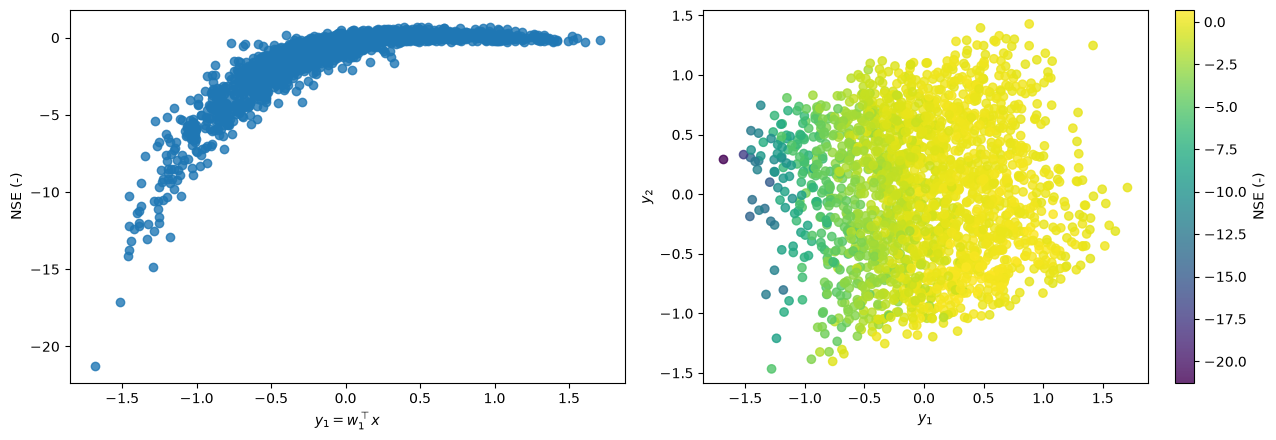

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ac.plotting.plot_sufficient_summary(subs[0], X=X, f=f[:, 0], dims=1, qoi_label=qlabels[0], ax=axes[0])
ac.plotting.plot_sufficient_summary(ac.with_dimension(subs[0], 2), X=X, f=f[:, 0], dims=2, qoi_label=qlabels[0], ax=axes[1])
fig.tight_layout()
plt.close(fig)
XN = space.to_normalized(X)
Y = XN @ subs[0].W[:, :2]
print(f'NSE: y1 in [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}], corr(y1, NSE) = {np.corrcoef(Y[:, 0], f[:, 0])[0, 1]:.4f}, '
      f'Spearman = {np.corrcoef(np.argsort(np.argsort(Y[:, 0])), np.argsort(np.argsort(f[:, 0])))[0, 1]:.4f}')
top = f[:, 0] > 0.5
print(f'the {top.sum()} samples with NSE > 0.5 have y1 in [{Y[top, 0].min():.2f}, {Y[top, 0].max():.2f}] and y2 in '
      f'[{Y[top, 1].min():.2f}, {Y[top, 1].max():.2f}]')
fig

The one-dimensional plot (left) shows a tight, concave trend: the NSE falls steeply for $y_1 < 0$, where the model over-predicts the flow, and levels off near its best values for $y_1 > 0$; corr$(y_1, \mathrm{NSE}) = 0.7655$ and the rank correlation is 0.8642. The 36 samples with NSE > 0.5 all have $y_1$ in $[-0.03, 1.08]$. In the two-dimensional plot (right) the colour changes mostly along $y_1$; near the top of the NSE range the spread at fixed $y_1$ is what the second direction (mostly C0) describes.

Qmean: corr(y1, f) = 0.0489
Qpeak: corr(y1, f) = 0.8683
Qmean: |dQmean/dK2| (normalized) median 0.00314, largest 1.08e+03; the 20 largest are at K2 <= 9.00e-04 1/day; the 1 % of samples with the largest values carry 0.98 of sum (dQmean/dK2)^2


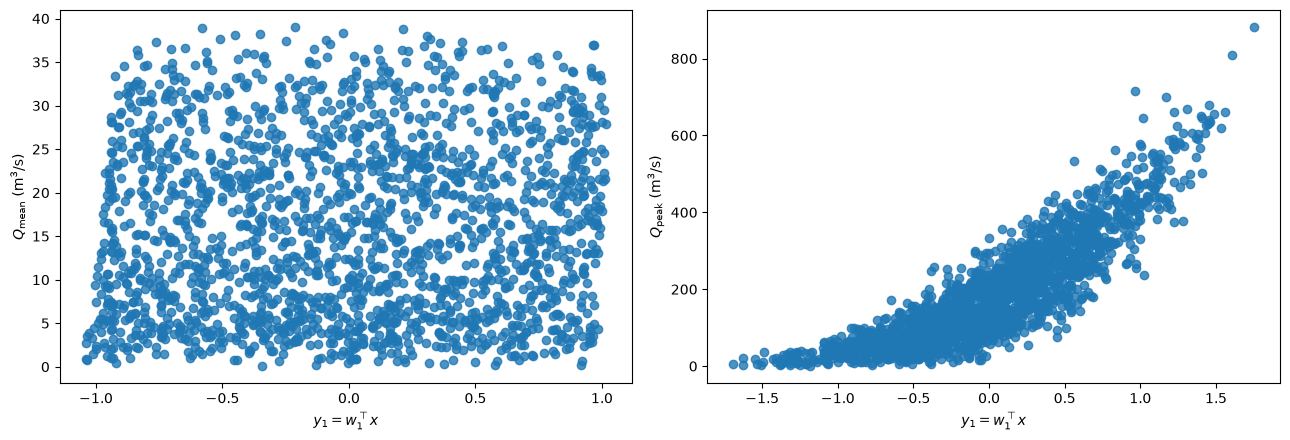

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, q in zip(axes, (1, 2)):
    ac.plotting.plot_sufficient_summary(subs[q], X=X, f=f[:, q], dims=1, qoi_label=qlabels[q], ax=ax)
fig.tight_layout()
plt.close(fig)
for q in (1, 2):
    y = XN @ subs[q].W[:, 0]
    print(f'{hm.QOI_NAMES[q]}: corr(y1, f) = {np.corrcoef(y, f[:, q])[0, 1]:.4f}')
k2 = X[:, 9]
big = np.abs(G[:, 1, 9]) * (hm.UB[9] - hm.LB[9]) / 2
print(f'Qmean: |dQmean/dK2| (normalized) median {np.median(big):.3g}, largest {big.max():.3g}; the 20 largest are at '
      f'K2 <= {np.sort(k2[np.argsort(-big)[:20]])[-1]:.2e} 1/day; the 1 % of samples with the largest values carry '
      f'{np.sort(big ** 2)[-len(big) // 100:].sum() / (big ** 2).sum():.2f} of sum (dQmean/dK2)^2')
fig

$Q_{\mathrm{peak}}$ (right) has a clear convex trend in its first active variable (corr 0.8683). $Q_{\mathrm{mean}}$ (left) shows none (corr 0.0489): its first eigenvector is K2 because $\partial Q_{\mathrm{mean}}/\partial K_2$ is enormous near $K_2 = 0$, where the slow reservoir barely drains and stores water through the window, and almost zero elsewhere. The 20 largest values occur at $K_2 \le 9.00\times10^{-4}$ day⁻¹, and the 1 % of samples with the largest values carry 0.98 of $\sum(\partial Q_{\mathrm{mean}}/\partial K_2)^2$. The average of gradient outer products is dominated by that thin corner, so for $Q_{\mathrm{mean}}$ the first one or two eigenvectors do not give a useful summary; the gradient-based subspace needs three dimensions, and a value-based direction does better (below).

**Dimension.** For the NSE we use $n = 1$: it is the largest eigenvalue gap (3.91), the one-dimensional subspace is well determined (bootstrap distance 0.047), and a cubic in $y_1$ has leave-one-out $R^2 = 0.906$ (below). The next ratio, $\lambda_2/\lambda_3 = 3.24$, is comparable and its bootstrap interval overlaps that of $\lambda_1/\lambda_2$; a second variable raises the leave-one-out $R^2$ only to 0.930, so $n = 2$ is a defensible alternative and we show both summary plots. For $Q_{\mathrm{peak}}$ we use $n = 2$ (gap 3.90 after $\lambda_2$; leave-one-out $R^2$ 0.814 with one variable, 0.910 with two) and for $Q_{\mathrm{mean}}$ $n = 3$ (gap 35.66 after $\lambda_3$; $R^2$ 0.967 with a quadratic in three variables against 0.115 with two).

**Checks of the gradients.** We repeat the estimate with the tangent derivative in the TT column instead of the 0.1 °C difference, and, for the NSE, estimate the first direction from the values alone with the quadratic principal Hessian directions (QPHD, a global quadratic fit to the $M = 2000$ values) and with the global linear model (OLS). We also give the OLS direction for $Q_{\mathrm{mean}}$.

In [11]:
# (a) the TT column: central differences (step 0.1 degC) vs the tangent, which misses the rain/snow jumps
for q in range(3):
    G2 = G[:, q].copy()
    G2[:, 0] = Gtt[:, q]
    s2 = ac.active_subspace(space=space, X=X, f=f[:, q], grads=G2, estimator='as')
    n = N_CHOSEN[q]
    d = np.linalg.norm(subs[q].W[:, :n].T @ s2.W[:, n:], 2)
    print(f'{hm.QOI_NAMES[q]}: tangent TT column: lambda_1/lambda_2 = {s2.eigenvalues[0] / s2.eigenvalues[1]:.2f}, '
          f'|w1 . w1(tangent)| = {abs(subs[q].W[:, 0] @ s2.W[:, 0]):.4f}, distance of the n = {n} subspaces {d:.3f}')
# (b) estimators that use values only
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for est in ('qphd', 'ols'):
        s = ac.active_subspace(space=space, X=X, f=f[:, 0], estimator=est, n=1)
        print(f'NSE, {est}: |w1 . w1(gradients)| = {abs(s.W[:, 0] @ subs[0].W[:, 0]):.4f}')
    s = ac.active_subspace(space=space, X=X, f=f[:, 1], estimator='ols', n=1)
    y = XN @ s.W[:, 0]
    big = np.argsort(-np.abs(s.W[:, 0]))[:3]
    print(f'Qmean, ols: w1 largest entries ' + ', '.join(f'{hm.NAMES[i]} {s.W[i, 0]:+.3f}' for i in big)
          + f'; corr(w1^T x, Qmean) = {abs(np.corrcoef(y, f[:, 1])[0, 1]):.4f}; '
          f'distance of the OLS direction from the n = 3 gradient subspace {np.linalg.norm(subs[1].W[:, 3:].T @ s.W[:, 0]):.3f}')

NSE: tangent TT column: lambda_1/lambda_2 = 3.97, |w1 . w1(tangent)| = 0.9967, distance of the n = 1 subspaces 0.081
Qmean: tangent TT column: lambda_1/lambda_2 = 1.82, |w1 . w1(tangent)| = 1.0000, distance of the n = 3 subspaces 0.023
Qpeak: tangent TT column: lambda_1/lambda_2 = 1.30, |w1 . w1(tangent)| = 0.9992, distance of the n = 2 subspaces 0.157
NSE, qphd: |w1 . w1(gradients)| = 0.9933
NSE, ols: |w1 . w1(gradients)| = 0.9965
Qmean, ols: w1 largest entries PM +0.950, FC -0.190, ETF -0.160; corr(w1^T x, Qmean) = 0.9783; distance of the OLS direction from the n = 3 gradient subspace 0.046


For the NSE the TT column changes little: with the tangent the NSE's $\lambda_1/\lambda_2$ is 3.97 and $|\mathbf w_1\cdot\mathbf w_1^{\mathrm{tangent}}| = 0.9967$. For $Q_{\mathrm{peak}}$, where TT has a larger share of the gradient, the two-dimensional subspaces differ by 0.157: **the $n = 2$ subspace of $Q_{\mathrm{peak}}$ depends on how the TT derivative is defined** (the ± 0.1 °C difference or the tangent), and at single samples the difference itself changes with the step, so its second direction should be read with this caveat. The value-only estimators agree with the gradient-based NSE direction ($|\mathbf w_1\cdot\mathbf w_1^{\mathrm{AS}}| = 0.9933$ for QPHD and 0.9965 for OLS), so neither the jumps in TT nor the kinks distort it. For $Q_{\mathrm{mean}}$ the global linear direction is dominated by PM ($+0.950$, then FC $-0.190$ and ETF $-0.160$), and $\mathbf w^T\mathbf x$ along it has correlation 0.9783 with $Q_{\mathrm{mean}}$: a single linear combination summarizes the mean flow well (more precipitation, more flow), and it lies inside the three-dimensional gradient subspace (distance 0.046), but the gradient average ranks it below the steep K2 corner.

#### Surrogates on the active variables

Polynomials (cubic in one and two active variables, quadratic in three) with their leave-one-out $R^2$.

NSE    n = 1, degree 3: LOO R^2 = 0.9061
NSE    n = 2, degree 3: LOO R^2 = 0.9303
NSE    n = 3, degree 2: LOO R^2 = 0.8888
Qmean  n = 1, degree 3: LOO R^2 = 0.0049
Qmean  n = 2, degree 3: LOO R^2 = 0.1150
Qmean  n = 3, degree 2: LOO R^2 = 0.9668
Qpeak  n = 1, degree 3: LOO R^2 = 0.8139
Qpeak  n = 2, degree 3: LOO R^2 = 0.9096
Qpeak  n = 3, degree 2: LOO R^2 = 0.9178


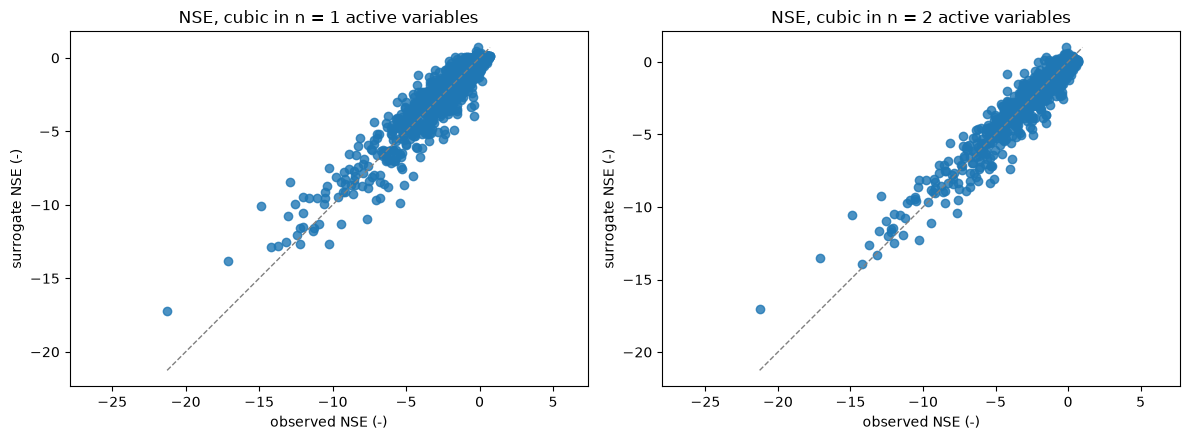

In [12]:
surs = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for q in range(3):
        for n, deg in ((1, 3), (2, 3), (3, 2)):
            s = ac.fit_surrogate(X=X, f=f[:, q], subspace=ac.with_dimension(subs[q], n), kind='poly', degree=deg)
            surs[q, n] = s
            print(f'{hm.QOI_NAMES[q]:6s} n = {n}, degree {deg}: LOO R^2 = {s.loo_r_squared:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, n in zip(axes, (1, 2)):
    ac.plotting.plot_surrogate_fit(surs[0, n], X=X, f=f[:, 0], qoi_label=qlabels[0], ax=ax)
    ax.set_title(f'NSE, cubic in n = {n} active variables')
fig.tight_layout()
plt.close(fig)
fig

For the NSE, a cubic in $y_1$ reaches leave-one-out $R^2 = 0.9061$ and a cubic in $(y_1, y_2)$ 0.9303; a quadratic in three variables does worse (0.8888) because the curvature of the NSE in $y_1$ needs more than degree 2. The remaining misfit is concentrated at the very negative NSE values (left figure). For $Q_{\mathrm{peak}}$ the cubics give 0.8139 and 0.9096, and for $Q_{\mathrm{mean}}$ the quadratic in three variables gives 0.9668, against 0.0049 and 0.1150 for the cubics in one and two.

### Comparison with the paper

The paper [[1]][R1] does not compute an active subspace, and it reports no sensitivity results for the Oldman case: its only HBV-SASK result is the factor-grouping dendrogram of Fig. 6 (p. 102), for the *Bow River at Banff*, based on "the sensitivity of mean-squared-errors performance metric on log-transformed simulated and observed streamflows over the historical record", with the parameters sorted from most to least influential: K2, PM, TT, ETF, FRAC, LP, β, FC, K1, α, C0, UBAS. That is a different basin and an output that weights low flows, so it is a reference, not a like-for-like check. For the Oldman NSE we compute Sobol' total-effect indices $S_T$ with the model (Jansen's estimator [[4]][R4], 1000 base samples, $1000\,(m+2) = 14000$ runs, 95 % bootstrap intervals from 500 resamples), and compare them with the activity scores $\alpha_i(n) = \sum_{k\le n}\lambda_k w_{ik}^2$ [[3]][R3] (normalized to sum to 1) and with the variance-based total effects (VARS-TO) printed in the VARS-TOOL tutorial "2 - SA of a real-world model", which uses the same output and window (STAR-VARS with 10 star centres; an outside output, not a result of the paper).

In [13]:
# Sobol' total-effect indices of NSE from the model (Jansen estimator, N = 1000 base samples, 14000 runs)
t0 = time.perf_counter()
rng_s = np.random.default_rng(SEED + 100)
N = 1000
A = hm.LB + (hm.UB - hm.LB) * rng_s.random((N, 12))
B = hm.LB + (hm.UB - hm.LB) * rng_s.random((N, 12))
fA, fB = hm.qoi(A)[:, 0], hm.qoi(B)[:, 0]
fAB = hm.qoi(np.vstack([np.where(np.arange(12) == j, B, A) for j in range(12)]))[:, 0].reshape(12, N)


def total_effects(idx):
    V = np.var(np.concatenate([fA[idx], fB[idx]]))
    return 0.5 * np.mean((fA[idx] - fAB[:, idx]) ** 2, axis=1) / V


ST = total_effects(np.arange(N))
rng_b = np.random.default_rng(SEED + 101)
boot = np.array([total_effects(rng_b.integers(0, N, N)) for _ in range(500)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
alpha1 = ac.activity_scores(subs[0], n=1)
alpha2 = ac.activity_scores(subs[0], n=2)
alpha12 = ac.activity_scores(subs[0], n=12)
print(f'{(N * 14)} model runs, {time.perf_counter() - t0:.0f} s')
print(f"{'param':6s} {'S_T':>6s} {'95 % interval':>15s} {'alpha(n=1)':>10s} {'alpha(n=2)':>10s} {'alpha(n=12)':>11s}   (alpha normalized to sum 1)")
for j in np.argsort(-ST):
    print(f'{hm.NAMES[j]:6s} {ST[j]:6.3f}  [{lo[j]:.3f}, {hi[j]:.3f}] {alpha1[j] / alpha1.sum():10.3f} '
          f'{alpha2[j] / alpha2.sum():10.3f} {alpha12[j] / alpha12.sum():11.3f}')
rank = lambda v: ', '.join(hm.NAMES[j] for j in np.argsort(-v)[:6])
print('order by S_T:        ', rank(ST))
print('order by alpha(n=2): ', rank(alpha2))
print('order by alpha(n=12):', rank(alpha12))
tut_st = {'TT': 0.038228, 'C0': 0.061175, 'ETF': 0.006297, 'LP': 0.007936, 'FC': 0.085894, 'beta': 0.00052,
          'FRAC': 0.664638, 'K1': 0.000665, 'alpha': 0.003789, 'K2': 0.013683, 'UBAS': 0.006557, 'PM': 0.36272}
print('order by VARS-TO of the VARS-TOOL tutorial (10 stars):',
      ', '.join(f'{k} {tut_st[k]:.3f}' for k in sorted(tut_st, key=lambda k: -tut_st[k])[:6]))

14000 model runs, 15 s
param     S_T   95 % interval alpha(n=1) alpha(n=2) alpha(n=12)   (alpha normalized to sum 1)
PM      0.705  [0.589, 0.837]      0.502      0.414       0.362
FRAC    0.437  [0.354, 0.531]      0.258      0.212       0.192
C0      0.163  [0.124, 0.210]      0.114      0.264       0.227
FC      0.145  [0.119, 0.176]      0.082      0.066       0.069
TT      0.056  [0.041, 0.073]      0.010      0.018       0.032
ETF     0.019  [0.015, 0.023]      0.005      0.004       0.009
alpha   0.013  [0.007, 0.021]      0.007      0.006       0.040
UBAS    0.013  [0.009, 0.017]      0.007      0.006       0.010
LP      0.013  [0.010, 0.016]      0.006      0.005       0.007
K2      0.012  [0.009, 0.015]      0.005      0.004       0.025
K1      0.012  [0.007, 0.017]      0.002      0.002       0.028
beta    0.001  [0.001, 0.002]      0.000      0.000       0.001
order by S_T:         PM, FRAC, C0, FC, TT, ETF
order by alpha(n=2):  PM, C0, FRAC, FC, TT, alpha
order by alpha(n=

| Quantity | Paper value | Notebook value |
|---|---|---|
| Parameter ranges | Table 2, p. 105 | the same 12 ranges (input table above) |
| Oldman basin area | 1434.73 km² (p. 105) | 1434.73 km² (VARS-TOOL set-up) |
| Mean annual precipitation, Oldman | 611 mm (p. 105) | 611 mm (forcing 1979–2008) |
| Mean annual streamflow at 05AA023 | 11.7 m³/s (p. 105) | 11.71 m³/s (observed 1979–2008) |
| Runoff ratio, Oldman | approximately 0.42 (p. 105) | 0.42 |
| Sensitivity of the Oldman NSE to the parameters | not reported | $S_T$: PM 0.705, FRAC 0.437, C0 0.163, FC 0.145, TT 0.056, all others ≤ 0.019 |
| Parameter order, most to least influential | Fig. 6, p. 102 (Bow River at Banff, MSE of log flows): K2, PM, TT, ETF, FRAC, LP, β, FC, K1, α, C0, UBAS | Oldman NSE, by $S_T$: PM, FRAC, C0, FC, TT, ETF; by $\alpha_i(2)$: PM, C0, FRAC, FC, TT, α |
| VARS-TOOL tutorial VARS-TO, Oldman NSE 1982–1996 (outside output, not the paper) | — | tutorial order FRAC, PM, FC, C0, TT, K2; our $S_T$ order PM, FRAC, C0, FC, TT, ETF |
| Active subspace | not reported | $n = 1$, $\lambda_1/\lambda_2 = 3.91$, $\mathbf w_1$ led by PM, FRAC, C0, FC |

The Oldman forcing reproduces the basin statistics of p. 105. For the NSE, our Sobol' total effects, the activity scores and the tutorial's VARS-TO pick out the same four parameters, PM, FRAC, C0 and FC, followed by TT; the order within the four differs. Our $S_T$ puts PM first (0.705, interval 0.589–0.837) and FRAC second (0.437), while the tutorial's 10-star estimate puts FRAC (0.665) ahead of PM (0.363); ten star centres give a much noisier estimate than our 14000 runs, so we read this as agreement on the set, not on the order. The activity scores with $n = 2$ move C0 ahead of FRAC, because the second eigenvector is mostly C0. The Banff ranking of Fig. 6 shares PM and TT near the top but puts the slow-reservoir coefficient K2 first and C0 near the bottom; a log-flow error weights the winter baseflow that K2 controls, and the Bow basin's runoff ratio (0.7, p. 105) differs from the Oldman's (0.42), so the difference is expected and is not a discrepancy.

### References

[1] S. Razavi, R. Sheikholeslami, H. V. Gupta, and A. Haghnegahdar. [VARS-TOOL: A toolbox for comprehensive, efficient, and robust sensitivity and uncertainty analysis](https://doi.org/10.1016/j.envsoft.2018.10.005). *Environmental Modelling & Software*, 112:95–107, 2019. VARS-TOOL is at <https://github.com/vars-tool/vars-tool> (GPL-3.0; its HBV-SASK code was run as an outside check and not copied).

[2] G. Lindström, B. Johansson, M. Persson, M. Gardelin, and S. Bergström. [Development and test of the distributed HBV-96 hydrological model](https://doi.org/10.1016/S0022-1694(97)00041-3). *Journal of Hydrology*, 201(1–4):272–288, 1997.

[3] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[4] M. J. W. Jansen. [Analysis of variance designs for model output](https://doi.org/10.1016/S0010-4655(98)00154-4). *Computer Physics Communications*, 117(1–2):35–43, 1999.

[5] J. E. Nash and J. V. Sutcliffe. [River flow forecasting through conceptual models part I — A discussion of principles](https://doi.org/10.1016/0022-1694(70)90255-6). *Journal of Hydrology*, 10(3):282–290, 1970.

[6] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[R1]: https://doi.org/10.1016/j.envsoft.2018.10.005
[R2]: https://doi.org/10.1016/S0022-1694(97)00041-3
[R3]: https://doi.org/10.1016/j.ress.2017.01.013
[R4]: https://doi.org/10.1016/S0010-4655(98)00154-4
[R5]: https://doi.org/10.1016/0022-1694(70)90255-6

### Acknowledgments

The paper [[1]][R1] acknowledges support of the first, second and fourth authors in part by the first author's NSERC (Natural Sciences and Engineering Research Council of Canada) Discovery Grant, and partial support of the third author by the Australian Research Council through the Centre of Excellence for Climate System Science (grant CE110001028).

In [14]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 21.1 s
